<a href="https://colab.research.google.com/github/anshumanshukl1605/question-practice-/blob/master/Session_2_2_Fitting_a_First_Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [5]:
hours = np.array([1, 2, 3, 4, 5]).reshape(5, 1)
marks = np.array([12, 19, 33, 39, 52])

In [6]:
print(hours.shape)
print(marks.shape)

(5, 1)
(5,)


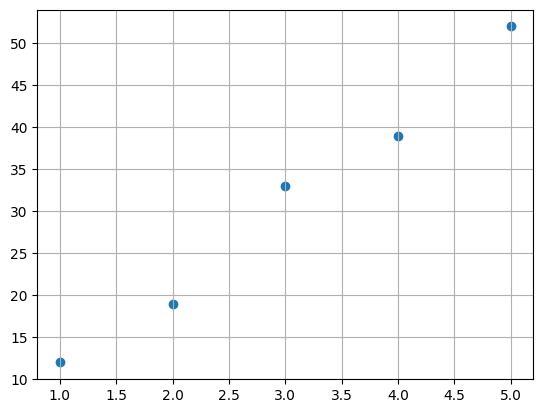

In [7]:
plt.scatter(hours, marks)
plt.grid('on');

In [10]:
model = LinearRegression()
model.fit(hours, marks)

LinearRegression()

In [11]:
model.coef_

array([10.])

In [ ]:
print("slope:", round(model.coef_[0], 2))
print("intercept:", round(model.intercept_, 2))

slope: 10.0
intercept: 1.0


In [ ]:
# predicted_marks = 10*hours + 1

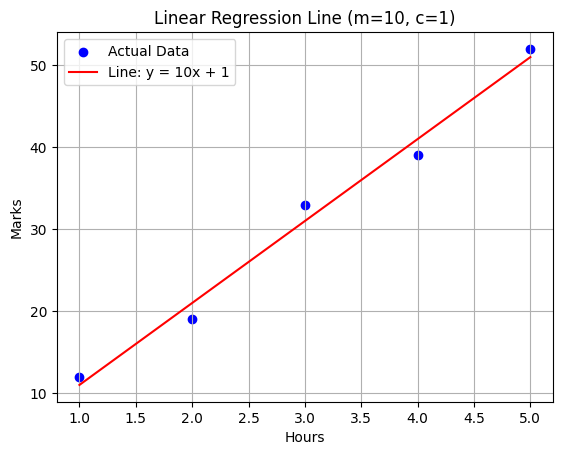

In [ ]:
# Calculate the predicted values for the line using m=10 and c=1
predicted_marks = 10 * hours + 1

# Plot the scatter plot of actual data
plt.scatter(hours, marks, color='blue', label='Actual Data')

# Plot the regression line
plt.plot(hours, predicted_marks, color='red', label='Line: y = 10x + 1')

# Add labels, title, grid, and legend
plt.xlabel('Hours')
plt.ylabel('Marks')
plt.title('Linear Regression Line (m=10, c=1)')
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
new_student = np.array([6]).reshape(1,1 )
new_student

array([[6]])

In [ ]:
model.predict(new_student)

array([61.])

In [ ]:

# House table: 200 houses
np.random.seed(11)
area = np.random.randint(400, 2000, 200)                   # area in square feet
price = 12 + 0.055 * area + np.random.normal(0, 9, 200)    # price in lakhs of rupees
houses = pd.DataFrame({"area_sqft": area, "price_lakhs": price.round(1)})

houses.head()

,area_sqft,price_lakhs
0,1504,108.5
1,1515,90.5
2,1761,99.5
3,1693,97.6
4,732,40.9


In [ ]:
print(houses.shape)

(200, 2)


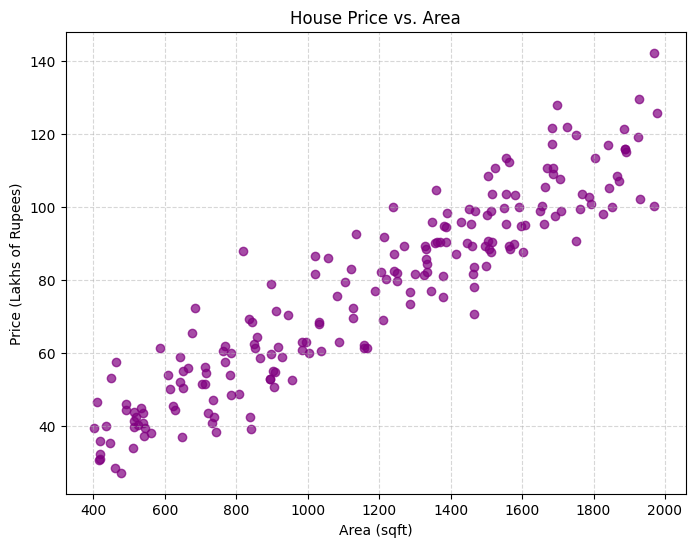

In [ ]:
# Create a scatter plot for house price and area
plt.figure(figsize=(8, 6))
plt.scatter(houses['area_sqft'], houses['price_lakhs'], color='purple', alpha=0.7)

# Add titles and labels
plt.title('House Price vs. Area')
plt.xlabel('Area (sqft)')
plt.ylabel('Price (Lakhs of Rupees)')
plt.grid(True, linestyle='--', alpha=0.5)

# Show the plot
plt.show()

In [ ]:
X = houses[["area_sqft"]]
y = houses['price_lakhs']

X.shape, y.shape

((200, 1), (200,))

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(160, 1) (40, 1)


In [ ]:
X_train

,area_sqft
79,1496
197,1429
38,1669
24,1750
122,540
...,...
106,865
14,540
92,1556
179,652


In [ ]:
scaler = StandardScaler()
scaler.fit(X_train) # learns mu and sig

StandardScaler()

In [ ]:
X_train_std = scaler.transform(X_train)
X_test_std = scaler.transform(X_test)

In [ ]:
house_model = LinearRegression()
house_model.fit(X_train_std, y_train)

LinearRegression()

In [ ]:
house_model.coef_, house_model.intercept_

(array([24.13291345]), np.float64(74.92687500000001))

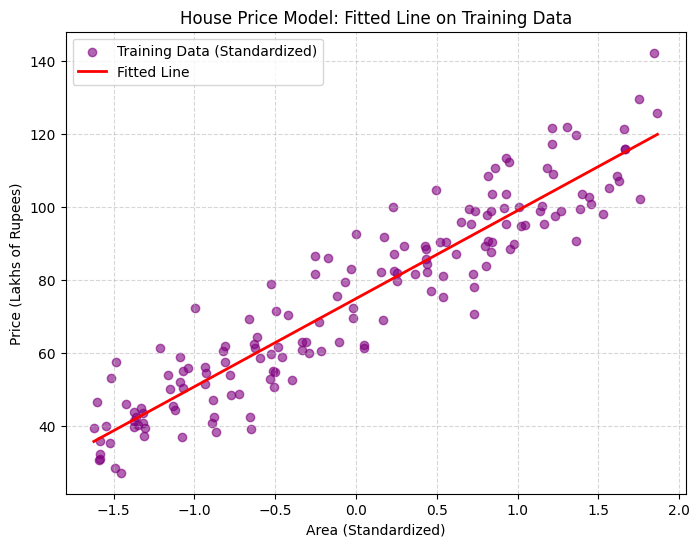

In [ ]:
# Predict using the fitted house model on the standardized training data
y_train_pred = house_model.predict(X_train_std)

# Create a plot with the standardized training points and the regression line
plt.figure(figsize=(8, 6))
plt.scatter(X_train_std, y_train, color='purple', alpha=0.6, label='Training Data (Standardized)')

# We sort the x-values to ensure the line plots smoothly
sort_idx = np.argsort(X_train_std.flatten())
plt.plot(X_train_std.flatten()[sort_idx], y_train_pred[sort_idx], color='red', linewidth=2, label='Fitted Line')

# Adding titles, labels, grid, and legend
plt.title('House Price Model: Fitted Line on Training Data')
plt.xlabel('Area (Standardized)')
plt.ylabel('Price (Lakhs of Rupees)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

In [ ]:
# Train a model on the unscaled training data
unscaled_model = LinearRegression()
unscaled_model.fit(X_train, y_train)

coef_unscaled = unscaled_model.coef_[0]
intercept_unscaled = unscaled_model.intercept_

print(f"Unscaled Coefficient (Slope): {coef_unscaled:.5f}")
print(f"Unscaled Intercept: {intercept_unscaled:.5f}")

Unscaled Coefficient (Slope): 0.05334
Unscaled Intercept: 14.37861


### Interpretation of the Unscaled Model:
- **Coefficient (Slope):** For every increase of **1 sqft** in area, the house price increases by approximately **{coef_unscaled:.5f} Lakhs of Rupees** (or about **{coef_unscaled * 100000:.0f} Rupees**).
- **Intercept:** The baseline price for a theoretical house with **0 sqft** is approximately **{intercept_unscaled:.2f} Lakhs of Rupees** (though note that 0 sqft is outside our training data range).

In [ ]:
# area = 1000 sqft
0.05334 * 1000 + 14.37861

67.71861

In [ ]:
unscaled_model.predict([[1000]]) # 1000sqft

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([67.716581])

In [ ]:
#  WRONG.... BAD BAD BAD......

new_house = np.array([[1000]])

house_model.predict(new_house)

# 242cr.

array([24207.84032537])

In [ ]:
# CORRECT approach - send standardised data.
new_house = np.array([[1000]])

new_house_std = scaler.transform(new_house)

house_model.predict(new_house_std)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([67.716581])

# Test data

In [ ]:
X_test_std = scaler.transform(X_test)

In [ ]:
y_pred = house_model.predict(X_test_std)
y_pred

array([ 52.83528626,  92.30538701,  91.55865538,  62.00941779,
        98.65260592,  99.82604135, 113.16053485,  69.31672022,
       103.18633371, 105.42652862,  51.87520273,  56.24891659,
        86.65156177,  58.00906974,  88.30503896,  40.56755224,
        82.91790359, 104.35976914,  94.81227179,  44.24787245,
        82.97124157, 117.05420695,  77.69078214,  84.99808458,
        97.69252239, 104.89314888,  59.34251909,  41.58097375,
       119.45441578,  88.03834909, 112.52047916, 115.29405381,
        50.38173945,  88.57172883,  79.34425933,  87.07826556,
        86.22485798,  76.57068469,  92.57207688, 110.60031209])

In [ ]:
y_test.values

array([ 43.7,  89.3,  90.1,  52.8, 103.3,  87.6, 100.1,  67.9, 105.5,
       107.7,  51.6,  59.9,  90.1,  87.9,  94.5,  44.4,  73.4, 110.7,
        88.6,  38.2,  76.8, 119.3,  77. ,  81.5,  89.4, 128. ,  68.6,
        34.1, 100.2,  94.8, 117.1, 115.2,  65.5,  98.5,  80.4,  90.5,
        95.9,  61.4,  83.6, 113.5])

In [ ]:
# R2 score.

from sklearn.metrics import r2_score

In [ ]:
r2_score(y_test, y_pred)

0.8279228689194076

In [ ]:
y_train.mean()

np.float64(74.92687500000001)